In [2]:
import pandas as pd
from scipy import stats
df = pd.read_excel('BIRDBASE v2025.1 Sekercioglu et al. Final.xlsx', sheet_name='Data', header=[0, 1])
body_mass_df = df['Body Mass']
bm_clean_df = body_mass_df.dropna()
display(bm_clean_df.head())
display(bm_clean_df.describe())
display(bm_clean_df.info())

,Female MinMass,Female MaxMass,Male MinMass,Male MaxMass,Unsexed MinMass,Unsexed MaxMass,Average Mass
0,90000.0,110000.0,100000.0,156000.0,86000.0,145000.0,114500.000000
27,395.0,548.0,358.0,482.0,490.0,600.0,478.833333
45,876.0,962.0,894.0,913.0,860.0,900.0,900.833333
50,271.6,361.2,299.5,368.8,211.0,384.0,316.016667
57,683.0,892.0,617.0,809.0,600.0,800.0,733.500000


,Female MinMass,Female MaxMass,Male MinMass,Male MaxMass,Unsexed MinMass,Unsexed MaxMass,Average Mass
count,2033.000000,2033.000000,2033.000000,2033.000000,2033.000000,2033.000000,2033.000000
mean,234.602263,342.692720,253.440610,379.095288,231.463114,390.139375,305.238895
std,2081.821168,2609.512238,2316.681766,3604.570685,2008.639898,3400.231244,2665.434039
min,1.900000,2.800000,1.800000,2.500000,2.280000,3.000000,2.416667
25%,14.500000,19.000000,14.000000,19.000000,13.400000,20.000000,17.000000
50%,33.000000,43.100000,33.000000,43.800000,31.000000,46.400000,38.316667
75%,98.000000,139.000000,97.000000,136.000000,95.000000,146.000000,120.666667
max,90000.000000,110000.000000,100000.000000,156000.000000,86000.000000,145000.000000,114500.000000


<class 'pandas.core.frame.DataFrame'>
Index: 2033 entries, 0 to 11586
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Female MinMass   2033 non-null   float64
 1   Female MaxMass   2033 non-null   float64
 2   Male MinMass     2033 non-null   float64
 3   Male MaxMass     2033 non-null   float64
 4   Unsexed MinMass  2033 non-null   float64
 5   Unsexed MaxMass  2033 non-null   float64
 6   Average Mass     2033 non-null   float64
dtypes: float64(7)
memory usage: 127.1 KB


None

In [3]:
bm_clean_df['Male Midpoint'] = bm_clean_df[['Male MinMass','Male MaxMass']].mean(axis=1)
bm_clean_df['Female Midpoint'] = bm_clean_df[['Female MinMass','Female MaxMass']].mean(axis=1)
display(bm_clean_df.head())
t_stat, p_val = stats.ttest_rel(bm_clean_df['Male Midpoint'], bm_clean_df['Female Midpoint'])
print(f"Test Statistic: {t_stat}")
print(f"P-value: {p_val}")

C:\Users\amoso\AppData\Local\Temp\ipykernel_9188\2245216284.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  bm_clean_df['Male Midpoint'] = bm_clean_df[['Male MinMass','Male MaxMass']].mean(axis=1)
C:\Users\amoso\AppData\Local\Temp\ipykernel_9188\2245216284.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  bm_clean_df['Female Midpoint'] = bm_clean_df[['Female MinMass','Female MaxMass']].mean(axis=1)


,Female MinMass,Female MaxMass,Male MinMass,Male MaxMass,Unsexed MinMass,Unsexed MaxMass,Average Mass,Male Midpoint,Female Midpoint
0,90000.0,110000.0,100000.0,156000.0,86000.0,145000.0,114500.000000,128000.00,100000.0
27,395.0,548.0,358.0,482.0,490.0,600.0,478.833333,420.00,471.5
45,876.0,962.0,894.0,913.0,860.0,900.0,900.833333,903.50,919.0
50,271.6,361.2,299.5,368.8,211.0,384.0,316.016667,334.15,316.4
57,683.0,892.0,617.0,809.0,600.0,800.0,733.500000,713.00,787.5


Test Statistic: 1.930529864382912
P-value: 0.05368020934521334


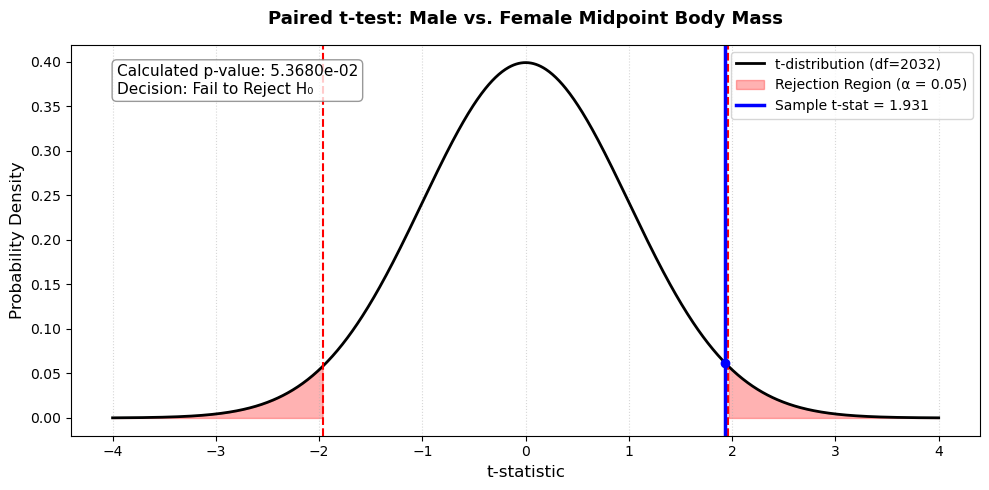

In [5]:
import matplotlib.pyplot as plt
import numpy as np

df_count = len(bm_clean_df) - 1

x_bound = max(4, abs(t_stat) + 1)
x = np.linspace(-x_bound, x_bound, 1000)
y = stats.t.pdf(x, df=df_count)
alpha = 0.05
t_crit_left = stats.t.ppf(alpha / 2, df=df_count)
t_crit_right = stats.t.ppf(1 - alpha / 2, df=df_count)

plt.figure(figsize=(10, 5))
plt.plot(x, y, color='black', linewidth=2, label=f't-distribution (df={df_count})')

plt.fill_between(x, y, where=(x <= t_crit_left), color='red', alpha=0.3, label='Rejection Region (α = 0.05)')
plt.fill_between(x, y, where=(x >= t_crit_right), color='red', alpha=0.3)
plt.axvline(t_crit_left, color='red', linestyle='--', linewidth=1.5)
plt.axvline(t_crit_right, color='red', linestyle='--', linewidth=1.5)

plt.axvline(t_stat, color='blue', linestyle='-', linewidth=2.5, label=f'Sample t-stat = {t_stat:.3f}')
plt.plot(t_stat, stats.t.pdf(t_stat, df=df_count), 'bo')
decision = "Reject H₀" if p_val < alpha else "Fail to Reject H₀"
text_str = f"Calculated p-value: {p_val:.4e}\nDecision: {decision}"
plt.gca().text(0.05, 0.95, text_str, transform=plt.gca().transAxes, fontsize=11,
               verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='gray'))
plt.title('Paired t-test: Male vs. Female Midpoint Body Mass', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('t-statistic', fontsize=12)
plt.ylabel('Probability Density', fontsize=12)
plt.legend(loc='upper right')
plt.grid(axis='x', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

We conduct a statistical test to compare the masses of male and female birds. Given that the dataset has "MinMass" and "MaxMass" of both sexes, we took the average of both columns to create "Midpoint" for each sex. We performed a two-sample t-test to determine if there was difference between the average mass of male and female birds. \
H0: Mean male mass = mean female mass\
Ha: mean male mass != mean female mass\
p-value = 0.05368 > 0.05 = alpha. Additionally, in the probability distribution graph, the test statistics, 1.93053, is out of the rejection region. Therefore, we fail to reject H0. There is insufficient evidence to suggest that the mean mass of male birds is different from the mean mass of female birds. \
This makes sense considering that half of bird species are monomorphic, meaning that males and females look nearly identical. As such, for half of bird species, males and females weigh nearly the same. 